## Single molecule tracking pipeline, python version
This script uploads a ready-to-use mask, as generated in omnipose, to database. To proceed, run the cells below by clicking the 'Play' button on the upper panel or select the cell and press Shift+Enter.

In [1]:
%load_ext dotenv
%dotenv config.env

In [2]:
%load_ext autoreload 
%autoreload 2

In [3]:
# Import the dependencies.

import os
import pandas as pd
import shutil
from ipyfilechooser import FileChooser

from utils.set_widgets import mask_chooser, filter_data
from utils.tiff_writer import show_mask
from utils.conditions_to_dict import conditions_to_df, analysis_meta
from utils.csv_writer import update_db_analysis, show_df_style


In [4]:
# Select the mask file generated in omnipose, .npy or .png
# .npy is preferred if available

im_path = os.getenv('SMPP_INPUT_DIR') # input folder
fc = FileChooser(im_path)
fc.filter_pattern = '*.npy'
display(fc)


FileChooser(path='/scratch/project_2009817/SMP_python_images', filename='', title='', show_hidden=False, selec…

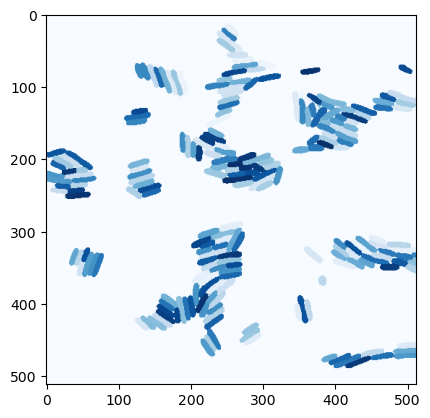

In [16]:
# Preview the mask file

m = show_mask(fc.selected_path, fc.selected_filename) 


In [6]:
# Click 'Play' to search across the database and choose the timelapse ('Raw Images') 
# corresponding to the mask you have chosen.

# Use the 'clear' function in the 'date' field to remove any unwanted entry.
# It is ok to use a comma and space to separate the row numbers in the 'exclude' and 'include' fields.
# Keep all the fields intact to view the entire database (though this may become inconvenient soon)

database = pd.read_csv(os.getenv('SMPP_DATABASE'), sep = '\t', dtype = 'str')
fields_list, fld_widgets_list, box = filter_data(database)
display(box)


In [17]:
# Run this cell when ready with the selection above,
# check if the file you choose is the one you want.

selected = conditions_to_df(database, fld_widgets_list, fields_list, 'Raw images')
selected


,name,date,dye,species,strain,temperature,medium,chemical,induction,comment,git_hash,uuid_experiment,uuid_fov,uuid_file,uuid_analysis,path
18408,Eveliny Nery,2026-10-20,NaN,Escherichia coli,Ec_64,"(np.float64(20.8), np.float64(20.94), np.float...",M9glyCAAT,NaN,NaN,261020_EN_Ec_64_M9glyCAAT_None_G.h5,344a2bf621a3b7d66cd857806a7971c80d32e63d,4c06a400-cd11-11f1-9186-080038cf4ae9,5516f31a-cd11-11f1-9186-080038cf4ae9,56705a3a-cd11-11f1-9186-080038cf4ae9,NaN,"('smt_1', '261020_EN_Ec_64_M9glyCAAT_None_G.h5')"


In [18]:
# Run this cell to generate analysis-level idetifiers.
# You may want to add a free-form comment specific to the file (optional),
# otherwise, press 'enter'.

try:
    git_hash, uuid_analysis, comment, filename = analysis_meta(selected, entry_type='mask')
except ValueError:
    print(file_meta(selected))


free form comment for this mask (optional): FV3


In [19]:
out_path = os.getenv('SMPP_DATA_DIR')+'/analysis/masks_omni/'
shutil.copyfile(fc.selected, out_path+filename)


'/projappl/project_2009817/Single-Molecule-Pipeline-Python/data//analysis/masks_omni/20261020_Nery_c32e5d8c.npy'

In [20]:
# Update the database, show the last 10 entries.
df = update_db_analysis(selected, comment, git_hash, uuid_analysis, out_path+filename, type='mask')
show_df_style(df.tail(10))


that's it, database updated:


,name,date,comment,uuid_experiment,uuid_fov,uuid_file,uuid_analysis
18402,Eveliny Nery,2026-10-20,nan,4c06a400-cd11-11f1-9186-080038cf4ae9,nan,nan,nan
18403,Eveliny Nery,2026-10-20,261020_EN_Ec_64_M9glyCAAT_None_B.h5,4c06a400-cd11-11f1-9186-080038cf4ae9,51ed19bc-cd11-11f1-9186-080038cf4ae9,51fe2ab8-cd11-11f1-9186-080038cf4ae9,nan
18404,Eveliny Nery,2026-10-20,261020_EN_Ec_64_M9glyCAAT_None_C.h5,4c06a400-cd11-11f1-9186-080038cf4ae9,51ed19bc-cd11-11f1-9186-080038cf4ae9,53570b82-cd11-11f1-9186-080038cf4ae9,nan
18405,Eveliny Nery,2026-10-20,261020_EN_Ec_64_M9glyCAAT_None_D.h5,4c06a400-cd11-11f1-9186-080038cf4ae9,53a7e1e2-cd11-11f1-9186-080038cf4ae9,53ba57a0-cd11-11f1-9186-080038cf4ae9,nan
18406,Eveliny Nery,2026-10-20,261020_EN_Ec_64_M9glyCAAT_None_E.h5,4c06a400-cd11-11f1-9186-080038cf4ae9,53a7e1e2-cd11-11f1-9186-080038cf4ae9,54c1329a-cd11-11f1-9186-080038cf4ae9,nan
18407,Eveliny Nery,2026-10-20,261020_EN_Ec_64_M9glyCAAT_None_F.h5,4c06a400-cd11-11f1-9186-080038cf4ae9,5516f31a-cd11-11f1-9186-080038cf4ae9,5528a61e-cd11-11f1-9186-080038cf4ae9,nan
18408,Eveliny Nery,2026-10-20,261020_EN_Ec_64_M9glyCAAT_None_G.h5,4c06a400-cd11-11f1-9186-080038cf4ae9,5516f31a-cd11-11f1-9186-080038cf4ae9,56705a3a-cd11-11f1-9186-080038cf4ae9,nan
18409,Eveliny Nery,2026-10-20,FV1,4c06a400-cd11-11f1-9186-080038cf4ae9,51ed19bc-cd11-11f1-9186-080038cf4ae9,53570b82-cd11-11f1-9186-080038cf4ae9,a79eb044-cd13-11f1-ba13-080038cf4ae9
18410,Eveliny Nery,2026-10-20,FV2,4c06a400-cd11-11f1-9186-080038cf4ae9,53a7e1e2-cd11-11f1-9186-080038cf4ae9,54c1329a-cd11-11f1-9186-080038cf4ae9,b7b8dc02-cd13-11f1-ba13-080038cf4ae9
18411,Eveliny Nery,2026-10-20,FV3,4c06a400-cd11-11f1-9186-080038cf4ae9,5516f31a-cd11-11f1-9186-080038cf4ae9,56705a3a-cd11-11f1-9186-080038cf4ae9,c32e5d8c-cd13-11f1-ba13-080038cf4ae9


In [16]:
# To upload a new mask, press 'Kernel' -> 'Restart Kernel'. 
# Otherwise, you can close the add_analysis_mask notebook, or shut down the interactive session.
